In [1]:
import pandas
import seaborn
from matplotlib import pyplot
from pandas.plotting import register_matplotlib_converters

from airpollutionforecasting.pipeline import run_pipeline
from airpollutionforecasting.eda.ts_correlation import TSCorrelationChecker

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-20 21:42:15.971 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [3]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])

2026-11-20 21:42:16.088 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-20 21:42:16.090 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-20 21:42:16.185 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-20 21:42:16.185 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-20 21:42:16.186 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-20 21:42:16.186 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-20 21:42:16.187 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-20 21:42:16.187 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

---
Lets observe PACF and ACF of the oryginal time series target (PM10 concetration)

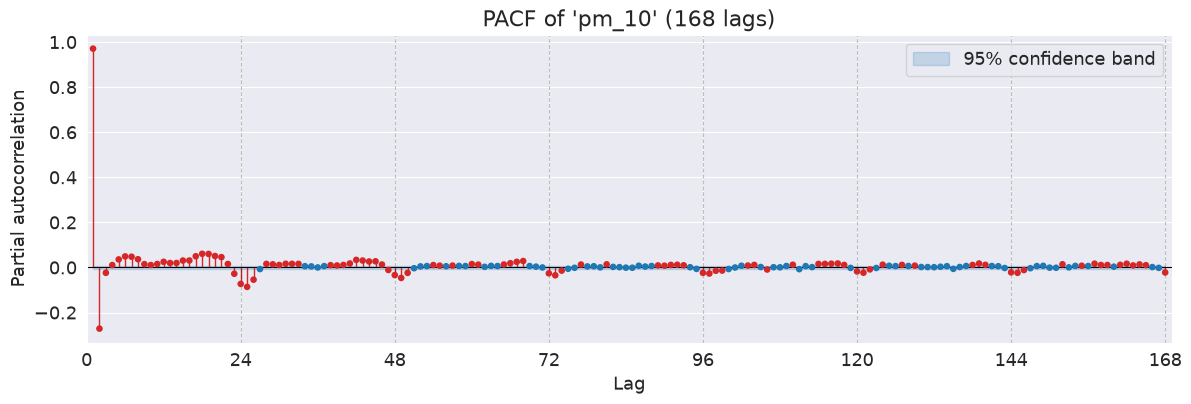

In [4]:
checker = TSCorrelationChecker(data, target_col="pm_10")

checker.plot_pacf_graph(
    nlags=168, seasonal_period=24
)  # daily guide lines every 24 lags
pyplot.show()

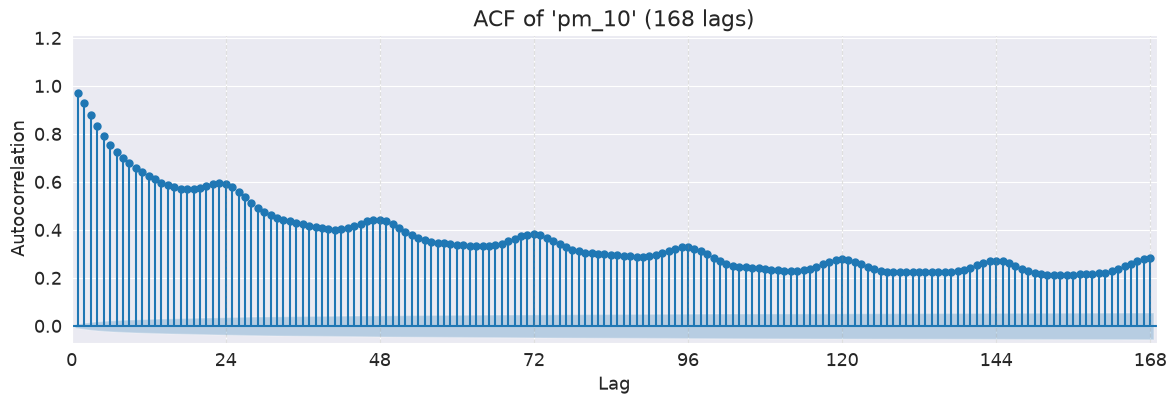

In [5]:
checker.plot_acf_graph(nlags=168)
pyplot.show()

---
### Differentiate the data to remove periodicity
Since we observe that correlations jump up every 24 hours, we can diffirientiate the 
time series to remove the effect of periodicity

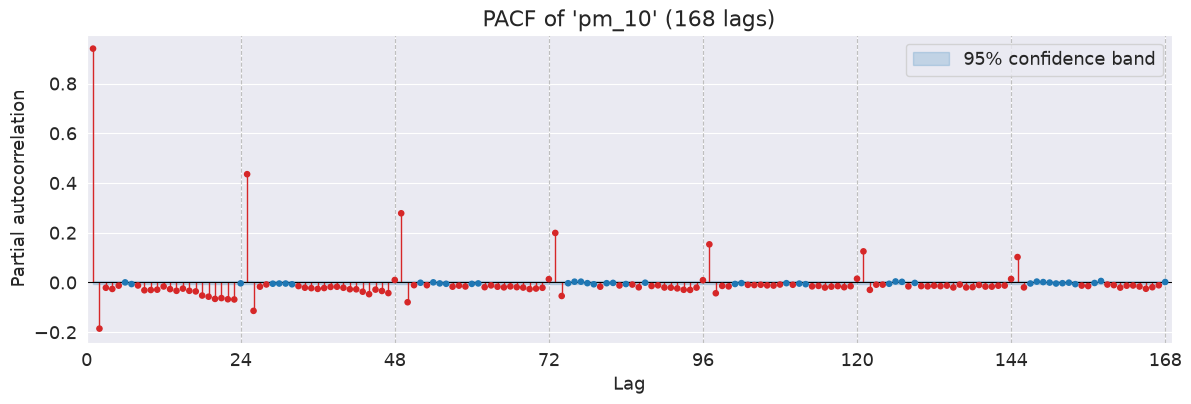

In [6]:
# remove daily cycle from the data and copy to not influence oryginal data
daily_data = data["pm_10"].diff(24).dropna().copy()

# plot PACF with removed daily cycle
daily_checker = TSCorrelationChecker(daily_data, target_col="pm_10")
daily_checker.plot_pacf_graph(
    nlags=168,
    seasonal_period=24,
)  # daily guide lines every 24 lags
pyplot.show()

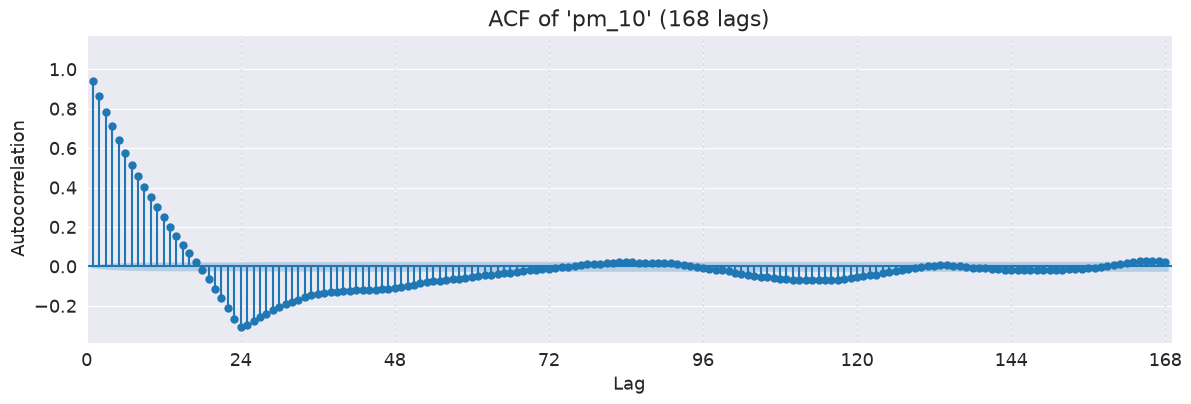

In [7]:
daily_checker.plot_acf_graph(nlags=168)
pyplot.show()

### Detrending the daily data
Since there is a trend that goes down in the data (check `notebooks/3-PW-Time-Series-Analysis-MSTL.ipynb` for MSTL decomposition) I will also check ACF after differentiation by 1. 
(DETRENDING)

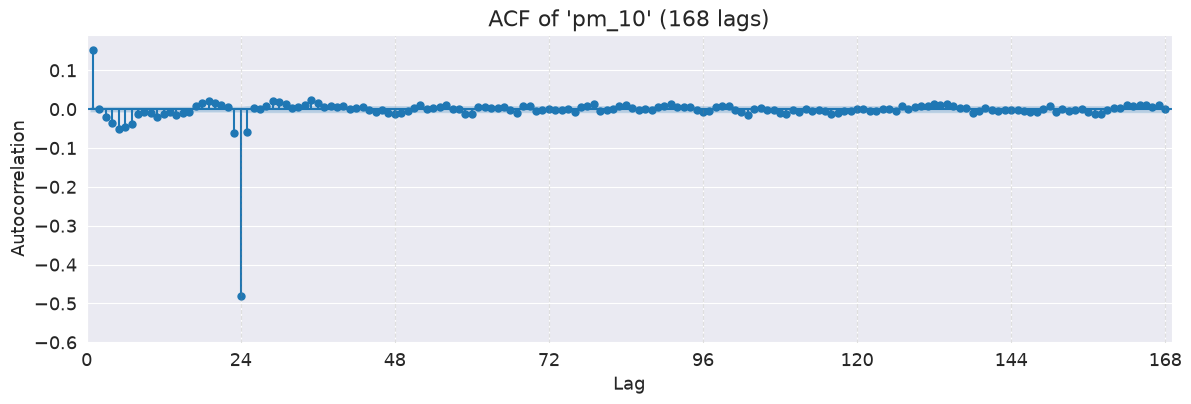

In [8]:
# check the ACF for detrended data
daily_detrended_data = daily_data.diff(1).dropna()
daily_detrended_checker = TSCorrelationChecker(daily_detrended_data, target_col="pm_10")
daily_detrended_checker.plot_acf_graph(nlags=168)
pyplot.show()

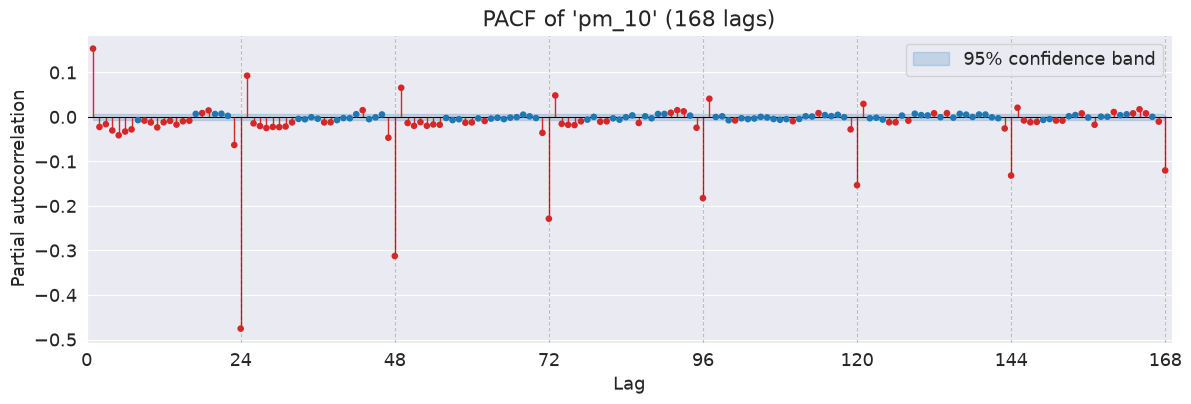

In [9]:
# plot PACF for fetrended data
daily_detrended_checker.plot_pacf_graph(
    nlags=168,
    seasonal_period=24,
)  # daily guide lines every 24 lags
pyplot.show()

---

### Observations
Lag 1 has ACF and PACF value of around 0.15.
After differencing at lag 24 and then at lag 1 we observe that most of the data is pure noise.
There is a single strong ACF spike at lag 24, and a PACF signal that slowly decays
across every 24 hours (24, 48, 72, ...).

This already gives us information about a possible SARIMAX model that could perform well:
`order = (p,d,q)`
- For p (AR order) a value of 1 may do the job, because of the lag 1 signal in the PACF.
- For d (differencing) we set the value 1, as we applied a lag-1 difference once.
- For q (MA order) I will also set the value of 1, because the lag 1 signal is also present
  in the ACF. The single lag 1 spike is ambiguous between AR and MA, so (1,1,1), (1,1,0)
  and (0,1,1) will be compared by AIC.

`seasonal_order = (P, D, Q, s)`
- s = 24 (season length)
- P = 0 (seasonal AR order), as the PACF does not cut off after lag 24 but decays
  across 24, 48, 72, ..., which is the signature of a seasonal MA term, not a seasonal AR term
- Q = 1 (seasonal MA order), as the ACF has a single spike at lag 24 and nothing at 48 or beyond
- D = 1 (seasonal differencing), as the lag-24 difference is applied once

The model is fitted on the raw series, as SARIMAX applies both differences internally.

---

## Correlation with other covariates in the data
### Check oryginal data correlations

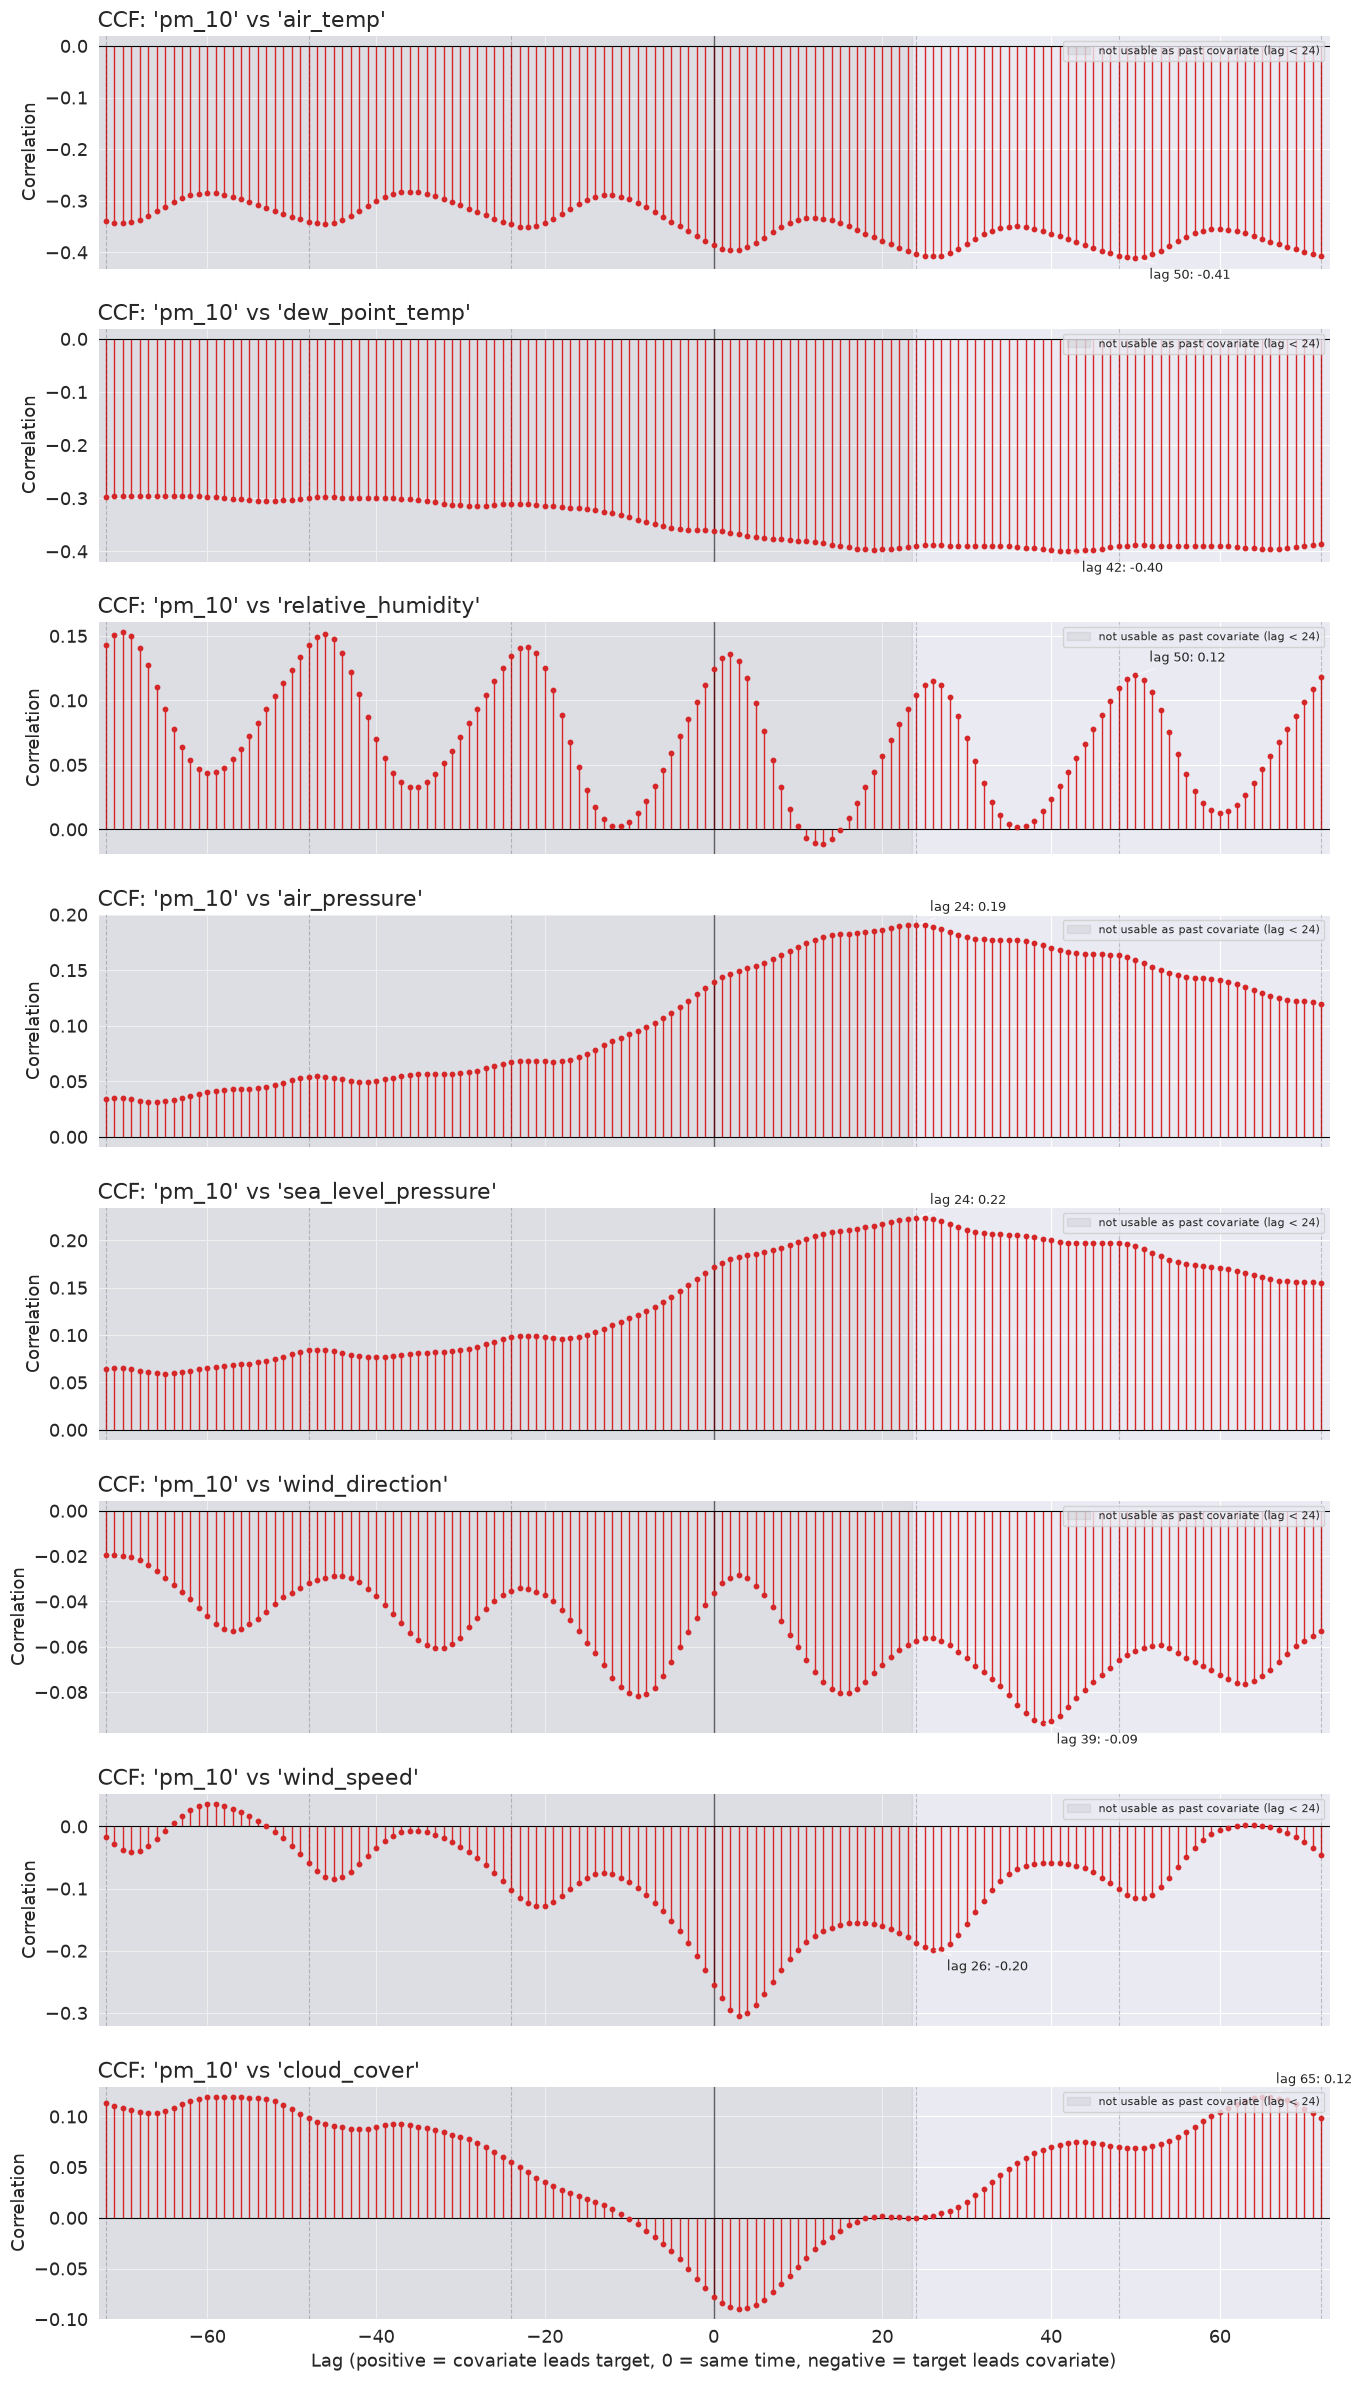

In [ ]:
# Raw vs differenced, 24h forecast horizon
checker.plot_ccf(horizon=24)
pyplot.show()

---


### Observations

**1. Temperatures**
In the raw (non-differenced) plot the correlation with PM10 stays roughly constant at about -0.4 across all lags. This points to a long-term shared trend or season rather than a lagged effect: temperature and PM10 drift together, which makes sense, since in winter it is colder and PM10 is higher (heating is a likely reason). 
Air temperature and dew point temperature behave almost identically.
**dew_point_temp can be dropped from the candidate list, as it carries almost the same information as air_temp.**
**air_temp stays as a feature because of the clear seasonal link, but its short-term effect is weak, so its value will be confirmed by validation error.**

**2. Relative humidity**
There is a clear 24-hour repeating pattern. The correlation peaks a few hours *before* the current PM10 value, so humidity from the last few hours is positively correlated with PM10. A plausible scenario is humidity rising in the morning and PM10 following a few hours later. 
**Keep humidity as a possible feature and check its effect on model performance.**

**3. Pressure**
The two pressure variables have the same dynamics, so they carry the same information. Higher pressure goes with higher PM10 (stagnant air), peaking at roughly 15 to 25 hours of lead.
**Drop sea_level_pressure and keep air_pressure.**

**4. Wind direction**
**The correlation is not meaningful, because 0° and 360° are the same direction, so a linear correlation on the raw angle is misleading.**
During feature building, create sin and cos features (or u/v wind components together with speed) and check whether they improve model performance.

**5. Wind speed and cloud cover**
Both show a clear negative correlation with PM10, strongest when the covariate leads by about 3 hours. Stronger wind goes with lower PM10, which fits dispersion. Higher cloud cover also goes with lower PM10, which is interesting. 
**Keep both as features, with wind speed as the top candidate.**


#### Sum up
All variables have a varying correlation over time and modeling specyfic relationships may be chalenging.
The way I want the model to make is to be able to pick what information is important and when, as I plan to train a model that predicts
airpolution for the next 12 hours.